<a href="https://colab.research.google.com/github/asulaiman27/Dell-Case-Study/blob/main/Dell-Case-Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# Load the parquet files into pandas DataFrames
calendar_df = pd.read_parquet('/content/calendar.parquet')
capacity_df = pd.read_parquet('/content/capacity.parquet')
expected_minutes_df = pd.read_parquet('/content/expected_minutes.parquet')
inference_df = pd.read_parquet('/content/inference.parquet')
train_df = pd.read_parquet('/content/train.parquet')

# Display the shapes of the loaded DataFrames
print("calendar_df shape:", calendar_df.shape)
print("capacity_df shape:", capacity_df.shape)
print("expected_minutes_df shape:", expected_minutes_df.shape)
print("inference_df shape:", inference_df.shape)
print("train_df shape:", train_df.shape)


calendar_df shape: (370, 17)
capacity_df shape: (191934, 4)
expected_minutes_df shape: (260, 4)
inference_df shape: (12069, 18)
train_df shape: (179853, 19)


# Kit End Date Prediction Pipeline



In [3]:
print("--- calendar_df ---")
print(calendar_df.info())
print("\n--- capacity_df ---")
print(capacity_df.info())
print("\n--- expected_minutes_df ---")
print(expected_minutes_df.info())
print("\n--- inference_df ---")
print(inference_df.info())
print("\n--- train_df ---")
print(train_df.info())

--- calendar_df ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 370 entries, 0 to 369
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   date                370 non-null    datetime64[ns]
 1   site                370 non-null    object        
 2   fiscal_year         370 non-null    int32         
 3   fiscal_qtr          370 non-null    int32         
 4   fiscal_month        370 non-null    int32         
 5   fiscal_qtr_weeknum  370 non-null    int32         
 6   fiscal_weeknum      370 non-null    int32         
 7   fisc_week_val       370 non-null    object        
 8   calendar_day        370 non-null    int32         
 9   day_of_week         370 non-null    int32         
 10  calendar_weeknum    370 non-null    int32         
 11  calendar_month      370 non-null    int32         
 12  calendar_year       370 non-null    int32         
 13  is_weekend          370 non-nu

In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Transform and Clean Data
# Convert quantities to numeric in train_df
train_df['quantity_produced'] = pd.to_numeric(train_df['quantity_produced'], errors='coerce')
train_df['line_qty'] = pd.to_numeric(train_df['line_qty'], errors='coerce')

# Create a continuous target variable for regression: Duration in hours
# (Since kit_end is a datetime, we predict the time taken from kit_start)
train_df['kit_duration_hours'] = (train_df['kit_end'] - train_df['kit_start']).dt.total_seconds() / 3600.0
train_df = train_df.dropna(subset=['kit_duration_hours'])

# 2. Join Datasets
# Join expected_minutes_df
df = train_df.merge(expected_minutes_df, on='family_desc', how='left')

# Join calendar_df on kit_start date and site
df['kit_start_date'] = df['kit_start'].dt.normalize()
calendar_df['date'] = pd.to_datetime(calendar_df['date'])
df = df.merge(calendar_df, left_on=['kit_start_date', 'site'], right_on=['date', 'site'], how='left')

# Join capacity_df (groupby to ensure uniqueness per date)
capacity_df['date'] = pd.to_datetime(capacity_df['date'])
cap_grouped = capacity_df.groupby('date')[['ot_hours', 'regular_hours']].sum().reset_index()
df = df.merge(cap_grouped, left_on='kit_start_date', right_on='date', how='left')

# Impute missing numeric values with median
numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

print("Joined data shape:", df.shape)

Joined data shape: (179853, 43)


In [5]:
# 3. Correlation Analysis
features = ['order_amt', 'quantity_produced', 'line_qty', 'expected_build_minutes',
            'expected_burn_minutes', 'calendar_day', 'day_of_week', 'is_weekend',
            'ot_hours', 'regular_hours', 'is_holiday']
features = [f for f in features if f in df.columns]

# Compute correlation matrix
corr_matrix = df[features].corr().abs()

# Select upper triangle of correlation matrix
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Find features with correlation greater than 0.8
to_drop = [column for column in upper.columns if any(upper[column] > 0.8)]
print("Highly correlated features to remove:", to_drop)

# Remove highly correlated variables
features = [f for f in features if f not in to_drop]
print("Final features used for modeling:", features)

Highly correlated features to remove: ['line_qty']
Final features used for modeling: ['order_amt', 'quantity_produced', 'expected_build_minutes', 'expected_burn_minutes', 'calendar_day', 'day_of_week', 'is_weekend', 'ot_hours', 'regular_hours', 'is_holiday']


In [8]:
# 4. Build Regression Models
X = df[features]
y = df['kit_duration_hours']

# Fill any remaining NaNs that weren't caught by median imputation
X = X.fillna(0)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model 1: Random Forest Regressor
rf = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_test)

# Model 2: Gradient Boosting Regressor
gbr = GradientBoostingRegressor(n_estimators=50, random_state=42)
gbr.fit(X_train, y_train)
gbr_preds = gbr.predict(X_test)

# Explain Model Metrics
def print_metrics(model_name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{model_name} -> RMSE: {rmse:.2f}, R-squared: {r2:.4f}")
    return rmse

print("--- Model Evaluation ---")
rf_rmse = print_metrics("Random Forest", y_test, rf_preds)
gbr_rmse = print_metrics("Gradient Boosting", y_test, gbr_preds)

best_model = "Random Forest" if rf_rmse < gbr_rmse else "Gradient Boosting"
print(f"\nThe best model is {best_model} because it has the lowest Root Mean Squared Error (RMSE).")

--- Model Evaluation ---
Random Forest -> RMSE: 26.09, R-squared: 0.5241
Gradient Boosting -> RMSE: 32.60, R-squared: 0.2567

The best model is Random Forest because it has the lowest Root Mean Squared Error (RMSE).


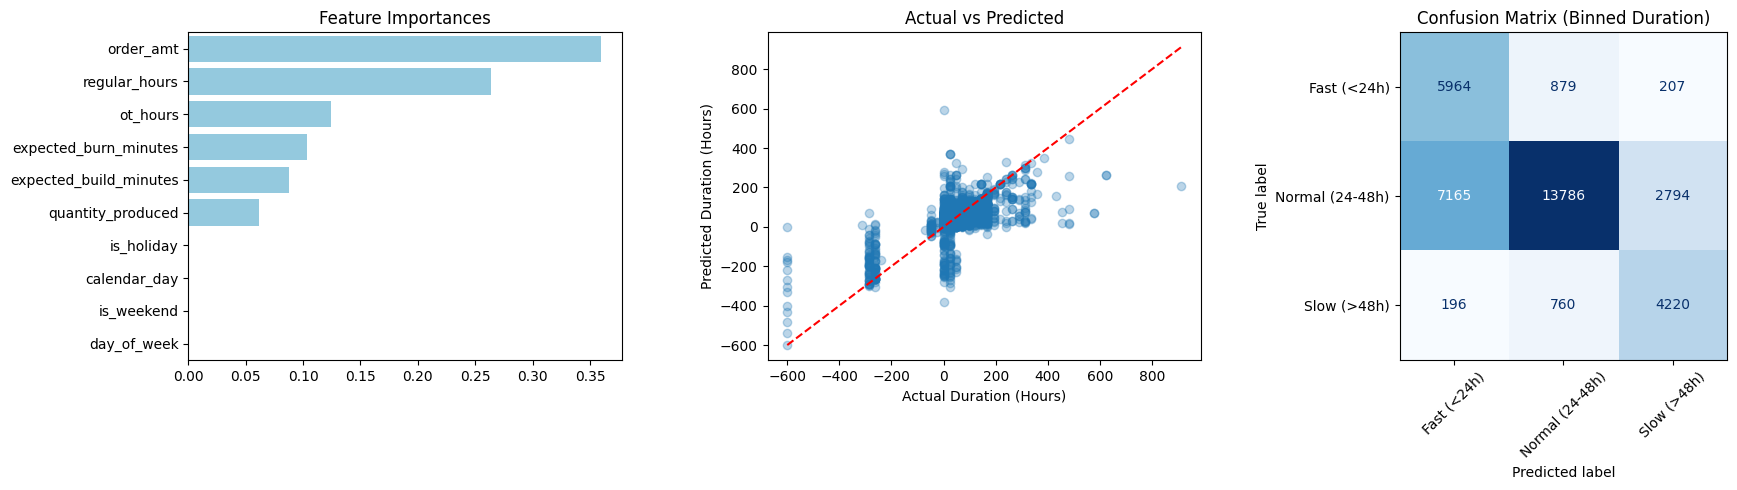

In [9]:
# 5. Plotting results
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# A) Variable Importance Plot (Random Forest)
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
sns.barplot(x=importances[indices], y=np.array(features)[indices], ax=axes[0], color='skyblue')
axes[0].set_title('Feature Importances')

# B) Actual vs Predicted (Best Model - assuming RF for plot)
axes[1].scatter(y_test, rf_preds, alpha=0.3)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[1].set_xlabel('Actual Duration (Hours)')
axes[1].set_ylabel('Predicted Duration (Hours)')
axes[1].set_title('Actual vs Predicted')

# C) Confusion Matrix (Binned Target)
# We bin continuous outputs into categorical ranges.
# Since quantiles overlap (mostly 24h), we use fixed bins.
bins = [y.min()-1, 23.9, 48.1, y.max()+1]
labels = ['Fast (<24h)', 'Normal (24-48h)', 'Slow (>48h)']

y_test_binned = pd.cut(y_test, bins=bins, labels=labels)
rf_preds_binned = pd.cut(rf_preds, bins=bins, labels=labels)

cm = confusion_matrix(y_test_binned, rf_preds_binned, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap='Blues', ax=axes[2], colorbar=False)
axes[2].set_title('Confusion Matrix (Binned Duration)')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [20]:
import pandas as pd
import numpy as np

# 1. Clean and Prepare Inference Data
inference_df['quantity_produced'] = pd.to_numeric(inference_df['quantity_produced'], errors='coerce')
inference_df['line_qty'] = pd.to_numeric(inference_df['line_qty'], errors='coerce')

# 2. Join Supplemental Datasets (Expected Minutes, Calendar, Capacity)
inf_merged = inference_df.merge(expected_minutes_df, on='family_desc', how='left')

inf_merged['kit_start_date'] = inf_merged['kit_start'].dt.normalize()
inf_merged = inf_merged.merge(calendar_df, left_on=['kit_start_date', 'site'], right_on=['date', 'site'], how='left')

inf_merged = inf_merged.merge(cap_grouped, left_on='kit_start_date', right_on='date', how='left')

# 3. Align Features and Handle Missing Values
X_inf = inf_merged[features]
X_inf = X_inf.fillna(0)

# 4. Generate Predictions using Best Model (Random Forest)
inference_predictions = rf.predict(X_inf)

# Display the NumPy array details
print("Predictions shape:", inference_predictions.shape)
print("First 10 predictions (Hours):", inference_predictions[:10])

Predictions shape: (12069,)
First 10 predictions (Hours): [19.20117953 54.31474993 20.71088017 11.12       56.64       35.04210139
 30.72       21.54857143 77.12571429 53.04      ]


In [21]:
import pandas as pd

# Create a DataFrame from the numpy array
predictions_df = pd.DataFrame(inference_predictions, columns=['predicted_duration_hours'])

# Save to a CSV file
output_path = '/content/inference_predictions.csv'
predictions_df.to_csv(output_path, index=False)

print(f"Successfully exported {len(predictions_df)} predictions to {output_path}")

Successfully exported 12069 predictions to /content/inference_predictions.csv
